In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.metrics import classification_report

In [4]:
train_data = pd.read_csv("C:/Users/TEJAS GAIKWAD/Downloads/titanic/train.csv")

In [5]:
test_data = pd.read_csv("C:/Users/TEJAS GAIKWAD/Downloads/titanic/test.csv")

In [6]:
print("Training Dataset:")
train_data.head()

Training Dataset:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [7]:
print("Testing Dataset:")
test_data.head()

Testing Dataset:


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [8]:
print("Dataset Shape:", train_data.shape)

Dataset Shape: (891, 12)


In [9]:
print("\nColumn Names:")
print(train_data.columns)


Column Names:
Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')


In [10]:
print("\nDataset Information:")
train_data.info()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [11]:
print("\nMissing Values:")
print(train_data.isnull().sum())


Missing Values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


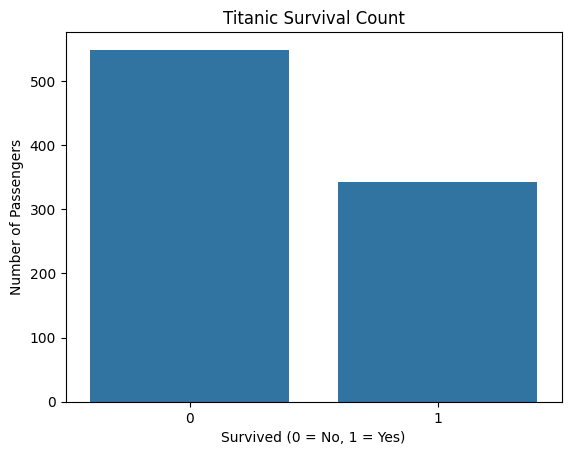

In [12]:
sns.countplot(data=train_data, x="Survived")
plt.title("Titanic Survival Count")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")
plt.show()

In [13]:
features = ["Pclass", "Sex", "Age", "SibSp",
            "Parch", "Fare", "Embarked"]

In [14]:
X = train_data[features]
y = train_data["Survived"]

In [15]:
print("Input Features:")
display(X.head())

Input Features:


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,male,22.0,1,0,7.2500,S
1,1,female,38.0,1,0,71.2833,C
2,3,female,26.0,0,0,7.9250,S
3,1,female,35.0,1,0,53.1000,S
4,3,male,35.0,0,0,8.0500,S


In [16]:
print("Target Values:")
print(y.head())

Target Values:
0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64


In [17]:
X = X.copy()
X["Age"] = X["Age"].fillna(X["Age"].median())
X["Fare"] = X["Fare"].fillna(X["Fare"].median())

In [23]:
X["Embarked"] = X["Embarked"].fillna(
    X["Embarked"].mode()[0])

In [25]:
X = pd.get_dummies(
    X, columns=["Sex", "Embarked"], dtype=int)

In [26]:
print("Processed Data:")
display(X.head())

Processed Data:


,Pclass,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,3,22.0,1,0,7.2500,0,1,0,0,1
1,1,38.0,1,0,71.2833,1,0,1,0,0
2,3,26.0,0,0,7.9250,1,0,0,0,1
3,1,35.0,1,0,53.1000,1,0,0,0,1
4,3,35.0,0,0,8.0500,0,1,0,0,1


In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

Training Samples: 712
Testing Samples: 179


In [28]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [29]:
y_pred = model.predict(X_test)

print("Actual Values:")
print(y_test.head(10).tolist())

print("\nPredicted Values:")
print(y_pred[:10].tolist())

Actual Values:
[0, 0, 1, 0, 1, 1, 1, 0, 0, 0]

Predicted Values:
[0, 0, 0, 0, 1, 0, 1, 0, 0, 0]


In [30]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 80.45 %


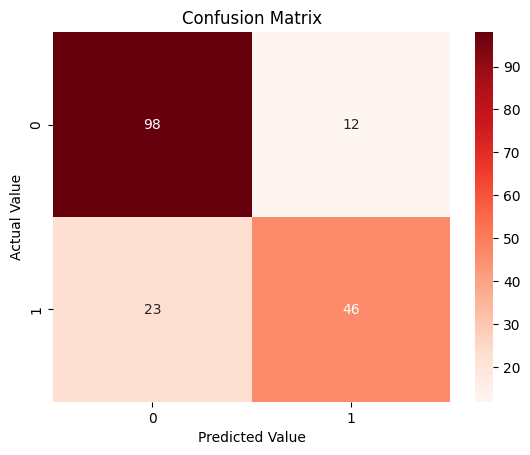

In [39]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Reds")

plt.title("Confusion Matrix")
plt.xlabel("Predicted Value")
plt.ylabel("Actual Value")
plt.show()

In [35]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



In [36]:
new_passenger = pd.DataFrame([{
    "Pclass": 1,
    "Age": 25,
    "SibSp": 0,
    "Parch": 0,
    "Fare": 80,
    "Sex_female": 1,
    "Sex_male": 0,
    "Embarked_C": 0,
    "Embarked_Q": 0,
    "Embarked_S": 1
}])

In [37]:
new_passenger = new_passenger.reindex(
    columns=X_train.columns, fill_value=0
)

prediction = model.predict(new_passenger)[0]
probability = model.predict_proba(new_passenger)[0][1]

print("Prediction:",
      "Survived" if prediction == 1 else "Did not survive")

print("Estimated survival probability:",
      round(probability * 100, 2), "%")

Prediction: Survived
Estimated survival probability: 94.17 %


In [38]:
print("Conclusion:")
print("Titanic Survival Prediction was implemented using")
print("Logistic Regression.")
print("The model predicts passenger survival using")
print("age, gender, ticket class, fare and family details.")
print("Accuracy:", round(accuracy * 100, 2), "%")

Conclusion:
Titanic Survival Prediction was implemented using
Logistic Regression.
The model predicts passenger survival using
age, gender, ticket class, fare and family details.
Accuracy: 80.45 %
